In [ ]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [148]:
plt.rcParams.update({
    "axes.titlesize": 16,   
    "axes.labelsize": 14,   
    "xtick.labelsize": 13,  
    "ytick.labelsize": 13,    
    "legend.fontsize": 12     
})

# IEEE-CIS EDA

In [2]:
df = pd.read_parquet("../data/raw.parquet")
print(df.shape, f"{df.memory_usage(deep=True).sum() / 1e6:.0f} MB")

(590540, 434) 969 MB


In [3]:
df.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,...,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,credit,315.0,87.0,19.0,NaN,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,325.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,debit,330.0,87.0,287.0,NaN,outlook.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,476.0,87.0,NaN,NaN,yahoo.com,NaN,2.0,5.0,0.0,0.0,0.0,4.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,420.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,...,NotFound,166.0,NaN,542.0,144.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


## Time

In [234]:
df['TransactionDT'].describe()

count    5.905400e+05
mean     7.372311e+06
std      4.617224e+06
min      8.640000e+04
25%      3.027058e+06
50%      7.306528e+06
75%      1.124662e+07
max      1.581113e+07
Name: TransactionDT, dtype: float64

In [235]:
df["day"] = df["TransactionDT"] // 86400
df["hour"] = df["TransactionDT"] // 3600 % 24
df[["TransactionDT", "day", "hour"]].describe()

,TransactionDT,day,hour
count,5.905400e+05,590540.000000,590540.000000
mean,7.372311e+06,84.729199,13.861923
std,4.617224e+06,53.437277,7.607152
min,8.640000e+04,1.000000,0.000000
25%,3.027058e+06,35.000000,6.000000
50%,7.306528e+06,84.000000,16.000000
75%,1.124662e+07,130.000000,20.000000
max,1.581113e+07,182.000000,23.000000


## Fraud distribution

In [248]:
daily = df.groupby('day').agg(n=('isFraud', 'size'), fraud_rate=('isFraud', 'mean'))

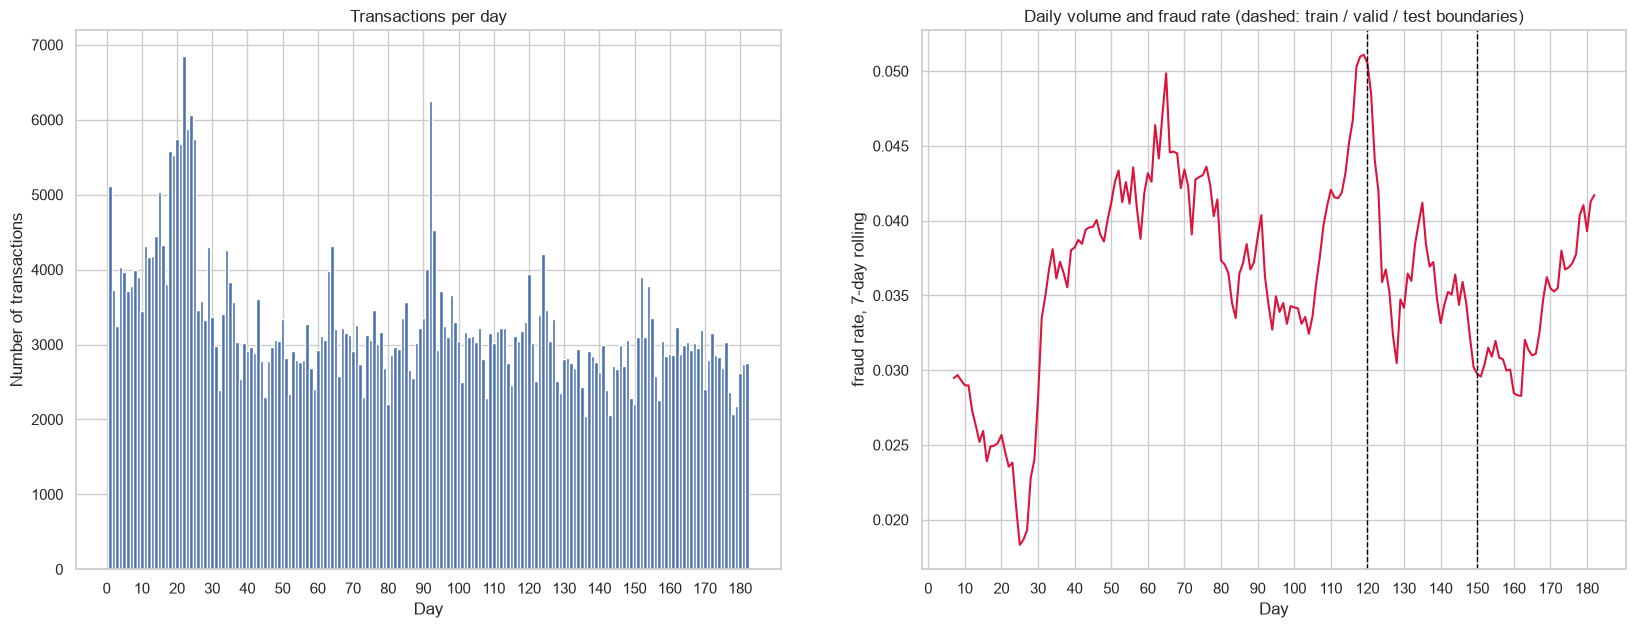

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 7))

ax[0].bar(daily.index, daily['n'], width=1.0)

ax[0].set_xlabel('Day')
ax[0].set_xticks(range(0, len(daily.index),10))
ax[0].set_ylabel('Number of transactions')
ax[0].set_title('Transactions per day')


ax[1].plot(daily.index, daily["fraud_rate"].rolling(7).mean(),color="crimson")

ax[1].set_xlabel('Day')
ax[1].set_xticks(range(0, len(daily.index),10))
ax[1].set_ylabel('fraud rate, 7-day rolling')

for d in (120, 150):
    ax[1].axvline(d, color="black", linestyle="--", linewidth=1)
ax[1].set_title("Daily volume and fraud rate (dashed: train / valid / test boundaries)")

plt.show()

Spikes in platform-wide daily volume (holiday season) do not raise the fraud rate: fraud is not driven by calendar traffic. Velocity has to be measured per card (uid_cnt_1h), not at the platform level.

In [239]:
df["part"] = pd.cut(
    df["day"],
    bins=[0, 120, 150, 183],
    labels=["train", "valid", "test"],
)

df.groupby("part", observed=True)["isFraud"].agg(n="size", fraud_rate="mean")

,n,fraud_rate
part,,
train,414542,0.035220
valid,83571,0.034103
test,92427,0.034763


The fraud rate is stable across the planned split (3.52% / 3.41% / 3.48%), so the weekly spikes above do not bias any period.

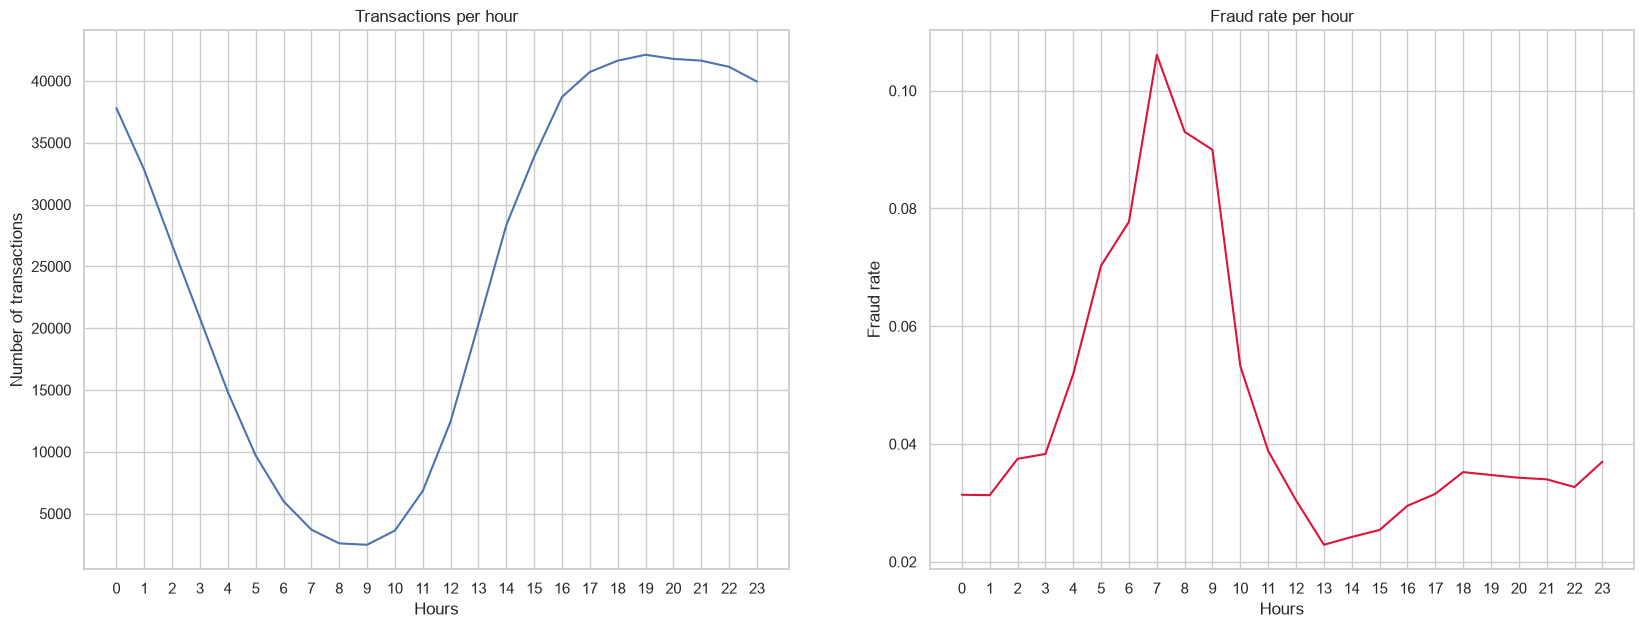

In [240]:
hours = df.groupby('hour').agg(fraud_rate=('isFraud','mean'))

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 7))

ax[0].plot(df['hour'].value_counts().sort_index())

ax[0].set_xlabel('Hours')
ax[0].set_xticks(range(0, 24))
ax[0].set_ylabel('Number of transactions')
ax[0].set_title('Transactions per hour')


ax[1].plot(hours.index, hours["fraud_rate"],color="crimson")

ax[1].set_xlabel('Hours')
ax[1].set_xticks(range(0, 24))
ax[1].set_ylabel('Fraud rate')
ax[1].set_title('Fraud rate per hour')

plt.show()

In [306]:
print(f"Share of transactions occurring at hours 5-10: {((df[(df['hour']>=5) & (df['hour']<=10)]['isFraud'].count().round(3))/df.shape[0]).round(3)}")
print(f"Fraud rate at hours 5-10: {(df[(df['hour']>=5) & (df['hour']<=10)]['isFraud'].mean().round(3))}")
print(f"Fraud rate at hours 5-10 / fraud rate hours 0-23: {((df[(df['hour']>=5) & (df['hour']<=10)]['isFraud'].mean().round(3))/(df['isFraud'].mean())).round(2)}")

Share of transactions occurring at hours 5-10: 0.048
Fraud rate at hours 5-10: 0.078
Fraud rate at hours 5-10 / fraud rate hours 0-23: 2.23


TransactionDT is an offset in seconds from an unknown reference, so the timezone is unknown. Volume is lowest at hours 5–10, which is most likely local night. These hours carry only 4.8% of transactions but a 7.8% fraud rate (2.23× the average), peaking at 10.6% at hour 7. The night window for the odd_hour signal is therefore 5–10.

In [241]:
df['isFraud'].value_counts(normalize=True)

isFraud
0    0.96501
1    0.03499
Name: proportion, dtype: float64

Only 3.5% of transactions are fraud. Accuracy and ROC-AUC are misleading at this imbalance, so the main model metric is PR-AUC, plus recall at a fixed 1% decline rate.

<Axes: xlabel='TransactionAmt', ylabel='Density'>

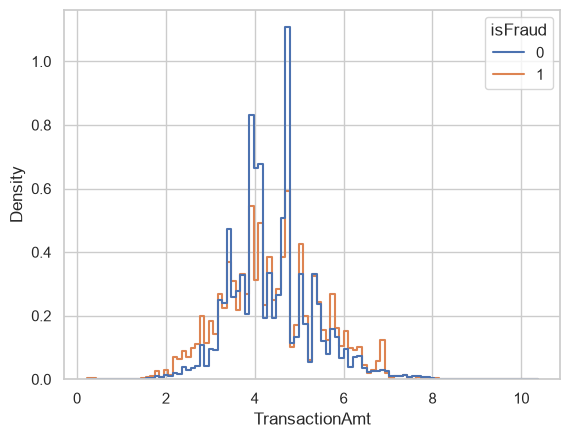

In [242]:
sns.histplot(data=df, 
             x=np.log1p(df["TransactionAmt"]), 
             hue="isFraud", 
             multiple="layer", 
             common_norm=False, 
             stat='density',
             element="step",
             fill=False,
             bins=100)

In [267]:
amt_bins = pd.cut(df["TransactionAmt"], [0, 5, 10, 25, 50, 100, 200, 500, 1000, np.inf])
df.groupby(amt_bins, observed=True)["isFraud"].agg(n="size", fraud_rate="mean").round(3)

,n,fraud_rate
TransactionAmt,,
"(0.0, 5.0]",1617,0.072
"(5.0, 10.0]",6212,0.079
"(10.0, 25.0]",43000,0.059
"(25.0, 50.0]",153695,0.030
"(50.0, 100.0]",164095,0.029
"(100.0, 200.0]",128041,0.030
"(200.0, 500.0]",71001,0.044
"(500.0, 1000.0]",15612,0.053
"(1000.0, inf]",7267,0.025


Fraud and legitimate amounts overlap heavily, so the absolute amount is a weak standalone feature. Fraud is over-represented at both ends of the typical range: payments under $25 have a 6–8% fraud rate (card testing) and $200–1,000 have 4.4–5.3% (cash-out), versus 3.5% overall and ~3% for $25–200. Very large payments (> $1,000) are less risky than average (2.5%). Implication: amount should enter the model relative to the card's usual spend (amt_to_uid_median) and as a count of small payments (micro_tests), not only as a raw value.

## Categorical features

In [243]:
def fraud_rate_by(col: str, min_count: int = 500) -> pd.DataFrame:
    """Fraud rate and volume per category (rare categories dropped)."""
    res = (
        df.groupby(col, observed=True, dropna=False)["isFraud"]
        .agg(n="size", fraud_rate="mean")
        .query("n >= @min_count")
        .sort_values("fraud_rate", ascending=False)
    )
    return res

To allow for reuse, I wrapped the code for calculating the number of transactions and the fraud rate across various categorical variables into a function.

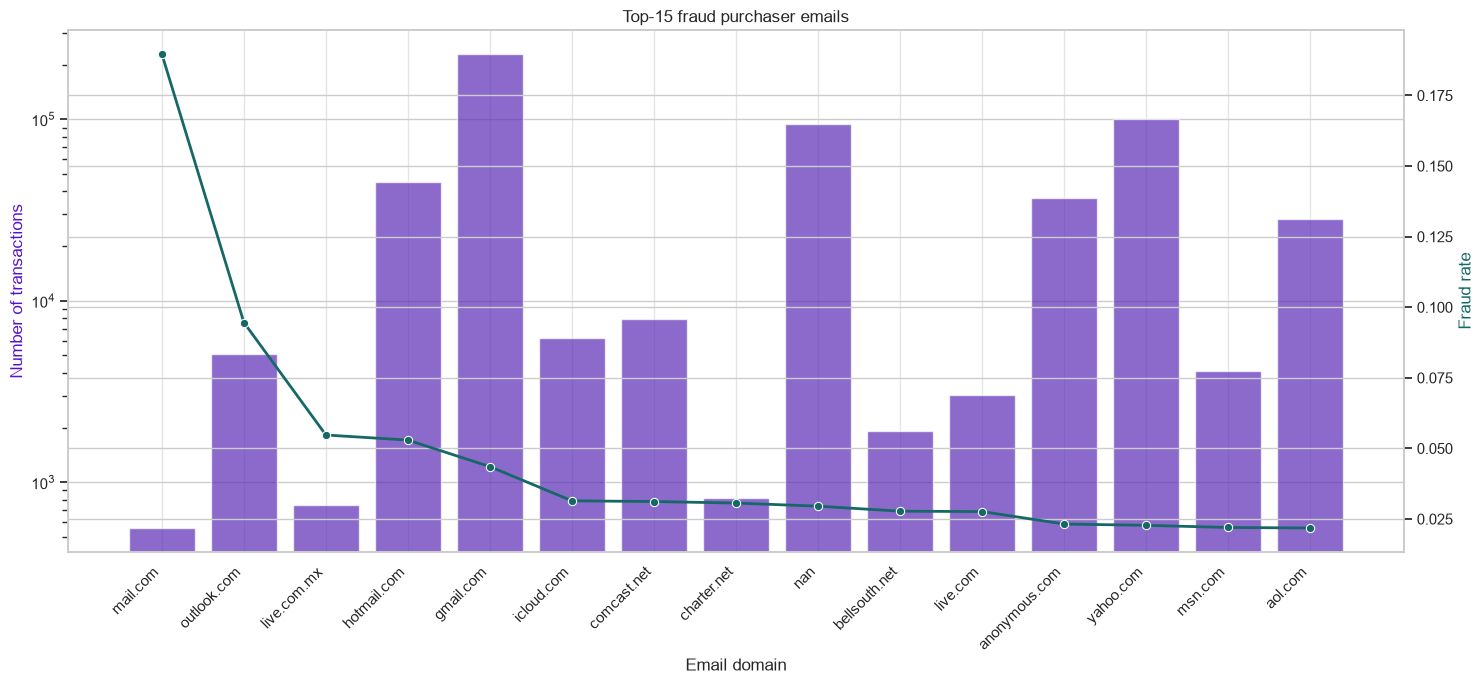

In [ ]:
fraud_by_email = fraud_rate_by("P_emaildomain")

top_frauds_by_email = fraud_by_email.iloc[:15,:].copy()
top_frauds_by_email.index = top_frauds_by_email.index.remove_unused_categories()

x_pos = list(range(len(top_frauds_by_email)))
x_labels = [str(val) for val in top_frauds_by_email.index]

fig, ax1 = plt.subplots(figsize=(15, 7))

sns.barplot(
    data=top_frauds_by_email,
    x=x_pos,
    y="n",
    color="#5314CD",
    alpha=0.7,
    ax=ax1
)
ax1.set_ylabel("Number of transactions", color="#5314CD")
ax1.set_xlabel("Email domain")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(x_labels, rotation=45, ha="right")
ax1.set_yscale('log')
ax1.grid(axis='x', linestyle='-', alpha=0.5)
ax1.set_axisbelow(True)

ax2 = ax1.twinx()

sns.lineplot(
    data=top_frauds_by_email,
    x=x_pos,
    y="fraud_rate",
    color='#166866',
    marker="o",
    linewidth=2,
    ax=ax2
)
ax2.set_ylabel("Fraud rate", color="#166866")

plt.title('Top-15 fraud purchaser emails')
plt.tight_layout()
plt.show()

In [321]:
print(f"Fraud rate in 'mail.com'(purchaser): {df[df['P_emaildomain']=='mail.com']['isFraud'].mean().round(3)}")
print(f"Fraud rate in 'mail.com' / fraud rate in all domains : {((df[df['P_emaildomain']=='mail.com']['isFraud'].mean())/(df['isFraud'].mean())).round(1)}")
print(f"Number of transactions in 'mail.com'(purchaser): {df[df['P_emaildomain']=='mail.com']['isFraud'].count().round(3)}")
print("-"*60)
print(f"Fraud rate in 'outlook.com'(purchaser): {df[df['P_emaildomain']=='outlook.com']['isFraud'].mean().round(3)}")
print(f"Fraud rate in 'outlook.com' / fraud rate in all domains : {((df[df['P_emaildomain']=='outlook.com']['isFraud'].mean())/(df['isFraud'].mean())).round(1)}")
number_outlook_transactions = df[df['P_emaildomain']=='outlook.com']['isFraud'].count().round(3)
print(f"Number of transactions in 'outlook.com'(purchaser): {number_outlook_transactions}")

Fraud rate in 'mail.com'(purchaser): 0.19
Fraud rate in 'mail.com' / fraud rate in all domains : 5.4
Number of transactions in 'mail.com'(purchaser): 559
------------------------------------------------------------
Fraud rate in 'outlook.com'(purchaser): 0.095
Fraud rate in 'outlook.com' / fraud rate in all domains : 2.7
Number of transactions in 'outlook.com'(purchaser): 5096


Fraud rate by purchaser email domain. "mail.com" has the highest fraud rate (19.0%, 5.4× the average), but on only 559 transactions; "outlook.com" follows with 9.5% on 5,096. Email domain is a useful categorical feature.

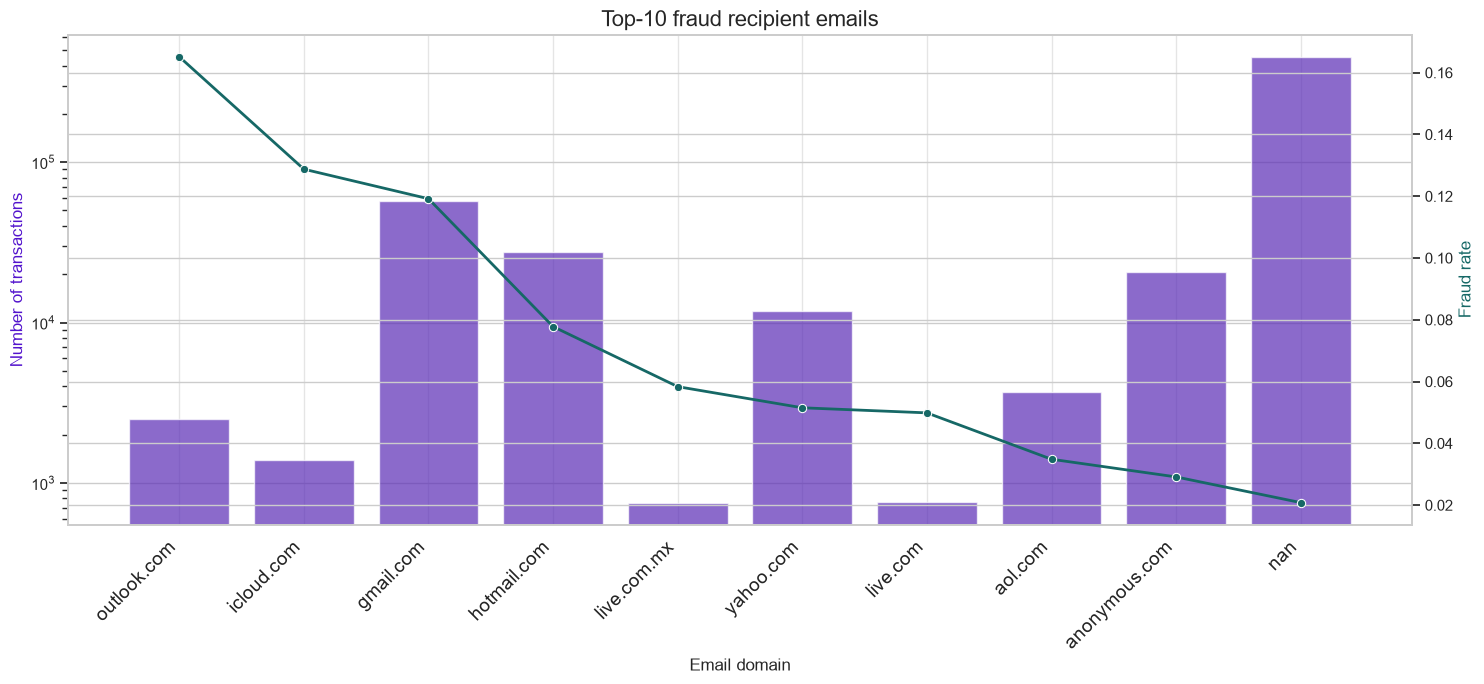

In [ ]:
fraud_by_r_emails = fraud_rate_by("R_emaildomain")

top_frauds_by_r_email = fraud_by_r_emails.iloc[:10,:].copy()
top_frauds_by_r_email.index = top_frauds_by_r_email.index.remove_unused_categories()

x_pos = list(range(len(top_frauds_by_r_email)))
x_labels = [str(val) for val in top_frauds_by_r_email.index]

fig, ax1 = plt.subplots(figsize=(15, 7))

sns.barplot(
    data=top_frauds_by_r_email,
    x=x_pos,
    y="n",
    color="#5314CD",
    alpha=0.7,
    ax=ax1
)
ax1.set_ylabel("Number of transactions", color="#5314CD")
ax1.set_xlabel("Email domain")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(x_labels, rotation=45, ha="right", fontsize=14)
ax1.set_yscale('log')
ax1.grid(axis='x', linestyle='-', alpha=0.5)
ax1.set_axisbelow(True)

ax2 = ax1.twinx()

sns.lineplot(
    data=top_frauds_by_r_email,
    x=x_pos,
    y="fraud_rate",
    color='#166866',
    marker="o",
    linewidth=2,
    ax=ax2
)
ax2.set_ylabel("Fraud rate", color="#166866")

plt.title('Top-10 fraud recipient emails', fontsize=16)
plt.tight_layout()
plt.show()

Fraud rate by recipient email domain. The highest figure is observed for the "outlook.com" domain (0.16); furthermore outlook.com is also the second-riskiest purchaser domain. "icloud.com" (0.13) and "gmail.com" (0.12) ranks second and third respectively in terms of the share of fraud. So these domains could be a useful feature for identifying fraudulent transactions.

In [317]:
df.groupby(df["R_emaildomain"].notna())["isFraud"].agg(n="size", fraud_rate="mean")

,n,fraud_rate
R_emaildomain,,
False,453249,0.020819
True,137291,0.081775


The very fact that a recipient's email address is provided serves as a risk signal for a fraudulent transaction. Transactions that include a recipient's email address have a fraud rate four times higher than those that do not.

In [355]:
both_outlook = df[(df['P_emaildomain']=='outlook.com') & (df['R_emaildomain']=='outlook.com')]['isFraud'].count()
print(f"number of transactions sent from 'outlook.com' and received at the same type of domain: {both_outlook}")
print(f"Share of such transactions out of all transactions from 'outlook.com': {(both_outlook/number_outlook_transactions).round(3)}")

print(f'Fraud rate among such transactions: {df[(df["P_emaildomain"] == "outlook.com") & (df["R_emaildomain"] == "outlook.com")]["isFraud"].mean().round(3)}')

number of transactions sent from 'outlook.com' and received at the same type of domain: 2182
Share of such transactions out of all transactions from 'outlook.com': 0.428
Fraud rate among such transactions: 0.179


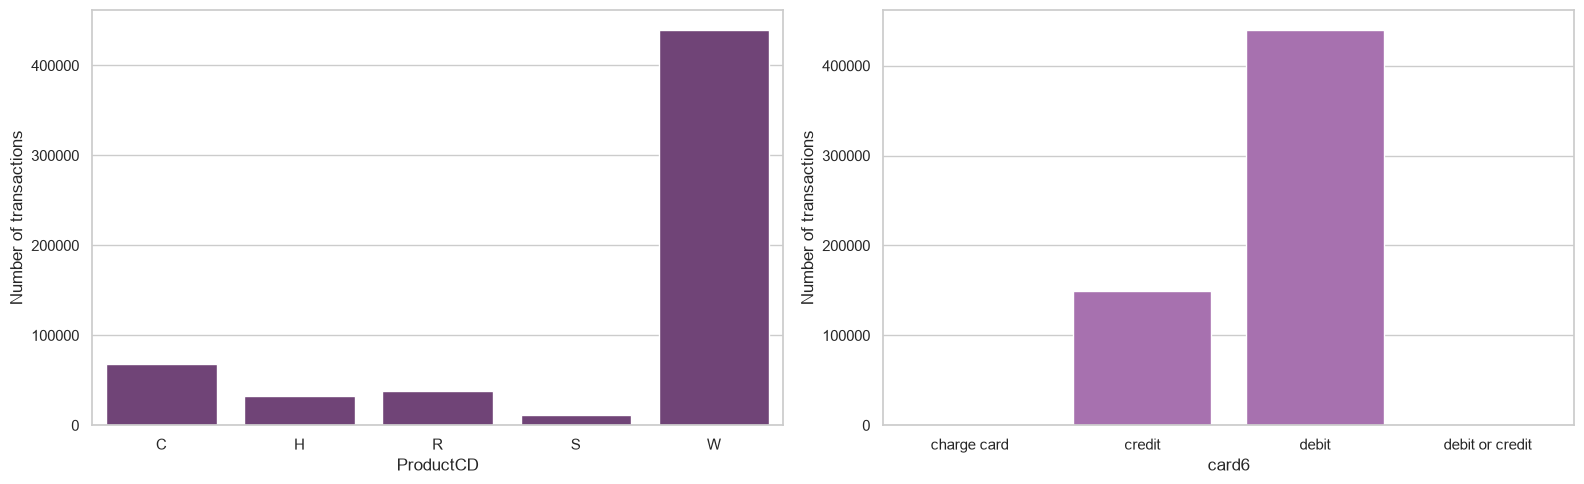

In [353]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

fraud_by_productcd = fraud_rate_by("ProductCD")
fraud_by_card6 = fraud_rate_by("card6")

sns.barplot(
    data= fraud_by_productcd,
    x=fraud_by_productcd.index,
    y=fraud_by_productcd['n'],
    ax=ax[0],
    color='#763B7F'
)
ax[0].set_ylabel('Number of transactions')

sns.barplot(
    data= fraud_by_card6,
    x=fraud_by_card6.index,
    y=fraud_by_card6['n'],
    ax=ax[1],
    color='#AE67B9'
)
ax[1].set_ylabel('Number of transactions')

plt.tight_layout()
plt.show()

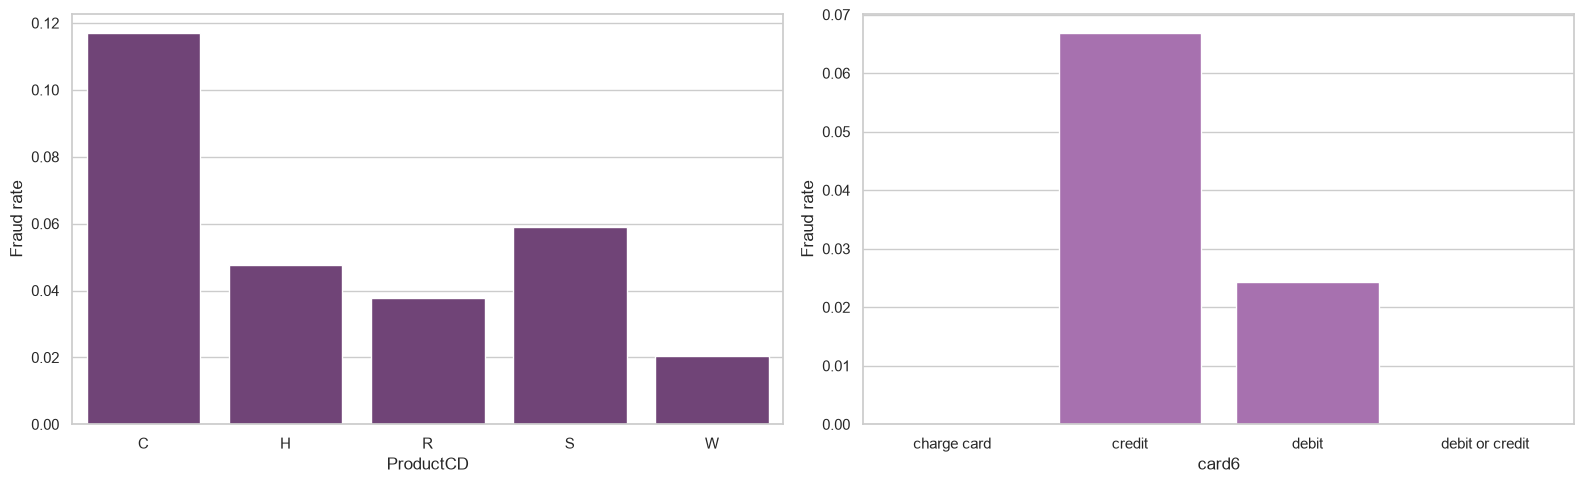

In [253]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

fraud_by_productcd = fraud_rate_by("ProductCD")
fraud_by_card6 = fraud_rate_by("card6")

sns.barplot(
    data= fraud_by_productcd,
    x=fraud_by_productcd.index,
    y=fraud_by_productcd['fraud_rate'],
    ax=ax[0],
    color='#763B7F'
)
ax[0].set_ylabel('Fraud rate')

sns.barplot(
    data= fraud_by_card6,
    x=fraud_by_card6.index,
    y=fraud_by_card6['fraud_rate'],
    ax=ax[1],
    color='#AE67B9'
)
ax[1].set_ylabel('Fraud rate')

plt.tight_layout()
plt.show()

In [327]:
fraud_by_productcd

,n,fraud_rate
ProductCD,,
C,68519,0.116873
S,11628,0.058996
H,33024,0.047662
R,37699,0.037826
W,439670,0.020399


In [340]:
print(f'Share of ProductCD=W out of all transactions: {((fraud_by_productcd.loc["W","n"])/(df.shape[0])).round(2)}')

Share of ProductCD=W out of all transactions: 0.74


In [341]:
fraud_by_card6

,n,fraud_rate
card6,,
credit,148986,0.066785
NaN,1571,0.024825
debit,439938,0.024263


ProductCD = C has the highest fraud rate (11.7%, twice the next product S at 5.9%), while W, 74% of volume, has only 2.0%. Credit cards are 2.8× riskier than debit (6.7% vs 2.4%).

In [254]:
fraud_rate_by('card4')

,n,fraud_rate
card4,,
discover,6651,0.077282
visa,384767,0.034756
mastercard,189217,0.034331
american express,8328,0.028698
NaN,1577,0.025999


In [347]:
fraud_by_card4 = fraud_rate_by('card4')
print(f'Share of "discover" card network out of all transactions: {(fraud_by_card4.loc["discover", "n"]/fraud_by_card4["n"].sum()).round(3)}')

Share of "discover" card network out of all transactions: 0.011


"Discover" card (0.077) network has fraud rate twice as high as that of Visa and Mastercard (0.034). It can be a useful feature for model construction. But card network = 'discover' is only 1.1% of the data.

In [255]:
fraud_rate_by('DeviceType')

,n,fraud_rate
DeviceType,,
mobile,55645,0.101662
desktop,85165,0.065215
NaN,449730,0.021017


In [350]:
449730/(449730+85165+55645)

0.7615572188166763

Mobile has the highest fraud rate (10.2%), then desktop (6.5%). Transactions with no identity record (76% of all) have only 2.1%. Having identity data at all is a strong risk signal: missing values must stay as a separate category, not be imputed.

In [231]:
na = df.isna().mean()
groups = na.index.str.extract(r"^([A-Za-z]+)", expand=False)
na.groupby(groups.values).describe()[["count", "mean", "min", "max"]]

,count,mean,min,max
C,14.0,0.000000,0.000000,0.000000
D,15.0,0.581513,0.002149,0.934099
DeviceInfo,1.0,0.799055,0.799055,0.799055
DeviceType,1.0,0.761557,0.761557,0.761557
M,9.0,0.499233,0.286788,0.593494
P,1.0,0.159949,0.159949,0.159949
ProductCD,1.0,0.000000,0.000000,0.000000
R,1.0,0.767516,0.767516,0.767516
TransactionAmt,1.0,0.000000,0.000000,0.000000
TransactionDT,1.0,0.000000,0.000000,0.000000


Identity columns id_* has 76–99% missing values, because an identity record exists for only 24% of transactions.

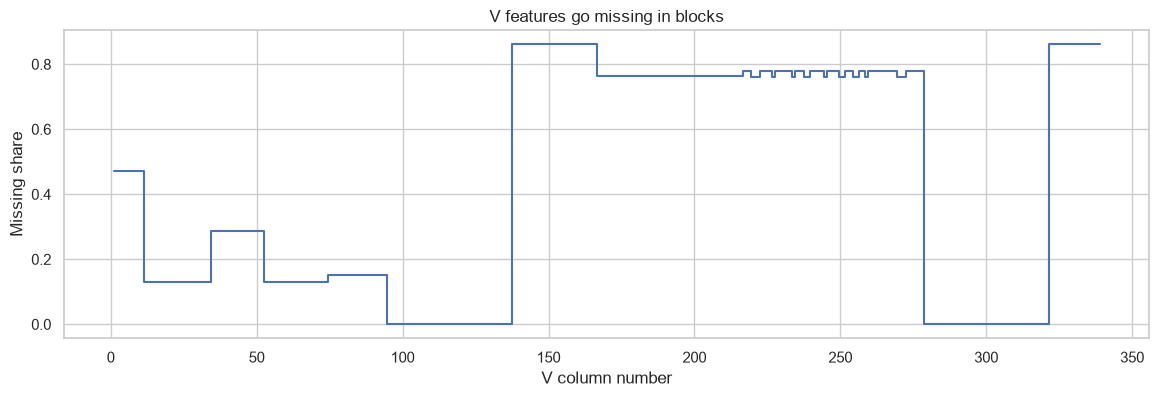

In [256]:
v_na = na.filter(regex=r"^V\d+$")
fig, ax = plt.subplots(figsize=(14, 4))
ax.step(range(1, len(v_na) + 1), v_na.values, where="mid")
ax.set_xlabel("V column number")
ax.set_ylabel("Missing share")
ax.set_title("V features go missing in blocks")
plt.show()

Columns with the same proportion of missing values ​​likely originate from the same source and tend to be missing together. This will be useful when we come to select features.

In [233]:
na.filter(regex=r"^V\d+$").round(4).value_counts().head(10)

0.7791    46
0.0005    43
0.0000    32
0.7636    31
0.8612    29
0.1288    23
0.1306    22
0.1510    20
0.7632    19
0.2861    18
Name: count, dtype: int64

## Thresholds

In [257]:
df[["TransactionAmt", "dist1"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99])

,TransactionAmt,dist1
count,590540.000000,238269.000000
mean,135.027176,118.502182
std,239.162521,371.872009
min,0.251000,0.000000
50%,68.769001,8.000000
90%,275.292999,268.000000
95%,445.000000,846.000000
99%,1104.000000,2040.000000
max,31937.390625,10286.000000


For the transaction amounts, the 95th percentile is 445, the 99th percentile is 1104, while the maximum is 31,937. This means that the majority of transactions do not exceed a value of 1104 and big TransactionAmt are really rare.

For the dist1, the 95th percentile is 846, the 99th percentile is 2040, while the maximum is 10,286. This means that the majority of distance do not exceed a value of 2040 and big dist1 are rare. p95 = 846 may be the threshold for geo_mismatch, but dist1 has also a 60% of missing values.

In [259]:
(df["TransactionAmt"] > 1104).groupby(df["isFraud"]).mean()

isFraud
0    0.009660
1    0.006582
Name: TransactionAmt, dtype: float64

In [262]:
(df["TransactionAmt"] < 5).groupby(df["isFraud"]).mean()

isFraud
0    0.002186
1    0.003968
Name: TransactionAmt, dtype: float64

Fraud is 1.8× more frequent among payments under $5 (0.40% vs 0.22%), but such payments are rare in absolute terms. Card testing will show up as a count of small payments per card within 24 h, not as a single small amount.

In [361]:
d = df.dropna(subset=["dist1"])
print(d.groupby(d["dist1"] > 846)["isFraud"].agg(n="size", fraud_rate="mean"))
print()

both = df.dropna(subset=["P_emaildomain", "R_emaildomain"])
same = both["P_emaildomain"].astype(str) == both["R_emaildomain"].astype(str)
print(both.groupby(same)["isFraud"].agg(n="size", fraud_rate="mean"))

            n  fraud_rate
dist1                    
False  226382    0.019286
True    11887    0.032725

            n  fraud_rate
False   23723    0.028748
True   102504    0.096504


| Signal | Rule | Evidence | Decision |
|---|---|---|---|
| `odd_hour` | hour in 5–10 | 7.8% fraud vs 3.5% overall (2.2×), 4.8% of volume | use |
| `micro_tests` | amount < $10 | 7.2–7.9% fraud (≈2.2×), 1.3% of volume | use; count-per-card threshold after velocity features |
| `geo_mismatch` | dist1 > 846 (p95) | 3.3% vs 1.9% below p95, but dist1 is 60% missing | weak, low priority |
| `recipient_mismatch` | P ≠ R email domain | 2.9% fraud when domains differ vs 9.7% when they match | use |

## Conclusions

1. **Imbalance drives the metric.** Only 3.5% of transactions are fraud, so accuracy and ROC-AUC are misleading. The main model metrics are PR-AUC and recall at a fixed 1% decline rate.

2. **The time split is sound.** The fraud rate is stable across train / valid / test (3.52% / 3.41% / 3.48%), and holiday volume spikes do not raise it. The split stays as planned (days 1–120 / 121–150 / 151–182); hyperparameters will be tuned with expanding-window validation inside days 1–150, and the test period is used once.

3. **Raw amount is weak; relative amount should be strong.** Fraud and legitimate amounts overlap heavily. Fraud concentrates at small payments (< $25: 6–8%) and mid-to-large ones ($500–1,000: 5.3%) versus ~3% for $25–200. Amount should be modelled relative to the card's usual spend and as a count of small payments per card.

4. **Context fields and their absence carry most of the signal.** `ProductCD = C` has 11.7% fraud (vs 2.0% for `W`, 74% of volume); credit cards are 2.8× riskier than debit. Transactions with an identity record are far riskier (mobile 10.2%, desktop 6.5%) than those without (2.1%, 76% of data), and a filled recipient email raises fraud from 2.1% to 8.2%. Missing values are informative and must stay as their own category rather than be imputed; V columns go missing in blocks, which will guide feature selection.

5. **EDA corrected two assumptions of the plan.** Local night is hours 5–10 in dataset time (7.8% fraud, 2.2× the average). Matching purchaser and recipient email domains is riskier than mismatching ones (9.7% vs 2.9%), so the `recipient_mismatch` signal must be revised `signals.yaml`.